In [ ]:
# 0.1
def fib_first(n):
    a, b = 0, 1
    result = []
    for x in range(n):
        result.append(a)
        a, b = b, a + b
    return result

print(fib_first(20))

[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610, 987, 1597, 2584, 4181]


In [ ]:
# 0.2
def tokenize(text):
    tokens = []
    i = 0
    while i < len(text):
        ch = text[i]
        if ch.isspace():
            i += 1
        elif ch.isdigit():
            j = i
            while j < len(text) and (text[j].isdigit() or text[j] == "."):
                j += 1
            tokens.append(float(text[i:j]))
            i = j
        elif ch in "+-*/()":
            tokens.append(ch)
            i += 1
        else:
            raise ValueError(f"Недопустимый символ: {ch}")
    return tokens


class Parser:
    def __init__(self, tokens):
        self.tokens = tokens
        self.pos = 0

    def peek(self):
        return self.tokens[self.pos] if self.pos < len(self.tokens) else None

    def take(self):
        tok = self.peek()
        self.pos += 1
        return tok

    def expr(self):
        value = self.term()
        while self.peek() in ("+", "-"):
            op = self.take()
            right = self.term()
            value = value + right if op == "+" else value - right
        return value

    def term(self):
        value = self.factor()
        while self.peek() in ("*", "/"):
            op = self.take()
            right = self.factor()
            if op == "*":
                value *= right
            else:
                if right == 0:
                    raise ZeroDivisionError("Деление на ноль")
                value /= right
        return value

    def factor(self):
        tok = self.take()
        if isinstance(tok, float):
            return tok
        if tok == "(":
            value = self.expr()
            if self.take() != ")":
                raise ValueError("Не закрыта скобка")
            return value
        if tok == "-":
            return -self.factor()
        raise ValueError(f"Неожиданный токен: {tok}")


def calculate(text):
    tokens = tokenize(text)
    if not tokens:
        raise ValueError("Пустое выражение")
    parser = Parser(tokens)
    result = parser.expr()
    if parser.peek() is not None:
        raise ValueError("Лишние символы в конце выражения")
    return result


print(calculate(input("Введите выражение: ")))

Введите выражение: 1+2
3.0


In [ ]:
# 0.3
import sys, time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print(sys.version)
print(np.__version__, pd.__version__, matplotlib.__version__)

def sum_sq_loop(n: int) -> int:
    # циклом for по целым числам Python
    s = 0
    for k in range(n):
        s += k * k
    return s

def sum_sq_numpy(n: int) -> int:
    # векторно
    return int(np.sum(np.arange(n, dtype=np.int64) ** 2))

def sum_sq_formula(n: int) -> int:
    # формула из вопроса 2
    return (n - 1) * n * (2 * n - 1) // 6

rows = []
for n in [10**4, 10**5, 10**6, 10**7]:
    t = time.perf_counter(); s_loop = sum_sq_loop(n);  t_loop = (time.perf_counter() - t) * 1000
    t = time.perf_counter(); s_np   = sum_sq_numpy(n); t_np   = (time.perf_counter() - t) * 1000
    rows.append({"n": f"10^{len(str(n))-1}", "S(n), цикл": s_loop, "S(n), NumPy": s_np,
                 "Совпадают?": "да" if s_loop == s_np else "нет",
                 "Время цикла, мс": round(t_loop, 2), "Время NumPy, мс": round(t_np, 2)})
    print("vse good" if s_loop == sum_sq_formula(n) else "ne good")      # проверка совпадения цикла с формулой
table3 = pd.DataFrame(rows)
table3

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
2.1.3 2.2.3 3.10.0
vse good
vse good
vse good
vse good


,n,"S(n), цикл","S(n), NumPy",Совпадают?,"Время цикла, мс","Время NumPy, мс"
0,10^4,333283335000,333283335000,да,0.88,1.09
1,10^5,333328333350000,333328333350000,да,10.40,1.54
2,10^6,333332833333500000,333332833333500000,да,111.93,14.43
3,10^7,333333283333335000000,1291890006563070912,нет,992.45,186.09


In [ ]:
# ЧАСТЬ 1. Основы Python
# 1.1 - Напишите функцию, которая принимает имя файла и возвращает его расширение.
# Если расширение определить невозможно (например, ’README’ или ’.bashrc’),
# функция возбуждает исключение

def get_extension(filename: str) -> str:
    if not isinstance(filename, str):
        raise TypeError("Имя файла должно быть строкой")
    name = filename.strip()
    if not name:
        raise ValueError("Пустое имя файла")
    pos = name.rfind(".") # индекс последней точки или -1
    if pos <= 0 or pos == len(name) - 1:
        raise ValueError(f"Не удалось определить расширение у '{filename}'")
    return name[pos + 1:]

def raises(func, exc, *args):
    try:
        func(*args)
    except exc:
        return True
    return False

assert get_extension("report.pdf") == "pdf"
assert get_extension("archive.tar.gz") == "gz"
assert get_extension(".config.json") == "json"
assert raises(get_extension, ValueError, "README")
assert raises(get_extension, ValueError, ".bashrc")
assert raises(get_extension, ValueError, "file.")
assert raises(get_extension, ValueError, "")
print("Проверки 1.1 пройдены")
for f in ["report.pdf", "README", ".bashrc"]:
    try:
        print(f, "gets from func -", get_extension(f))
    except ValueError as e:
        print(f, "gets ошибка:", e)

Проверки 1.1 пройдены
report.pdf gets from func - pdf
README gets ошибка: Не удалось определить расширение у 'README'
.bashrc gets ошибка: Не удалось определить расширение у '.bashrc'


In [ ]:
# 1.2 - Введите с клавиатуры две строки. Разбейте первую строку на слова и добавьте в
# конец полученного списка вторую строку целиком. Выведите список.

def words_plus_line(first: str, second: str) -> list[str]: # прототип
    result = first.split()
    result.append(second) # не extend
    return result

assert words_plus_line("a b c", "x y") == ["a", "b", "c", "x y"]
assert words_plus_line("", "x") == ["x"]
assert words_plus_line("  много   пробелов ", "z") == ["много", "пробелов", "z"]
assert words_plus_line("один", "") == ["один", ""]
print("Проверки 1.2 пройдены")

s1 = input("Первая строка: ")
s2 = input("Вторая строка: ")
print(words_plus_line(s1, s2))

Проверки 1.2 пройдены
Первая строка: опа
Вторая строка: опа опа
['опа', 'опа опа']


In [ ]:
# ЧАСТЬ 2. NumPy и pandas
# 2.1 - Дан массив формы (5, 5, 3) (например, изображение 5 × 5 с тремя цветовыми
# каналами) и массив формы (5, 5). Умножьте каждый канал первого массива на второй,
# используя транслирование.

rng = np.random.default_rng(7)

img  = rng.integers(0, 256, size=(5, 5, 3))   # "картинка"
mask = rng.random((5, 5))                     # коэффициенты 0-1

try:
    img * mask
except ValueError as e:
    print("Без добавления оси ошибка:", e)

# делает форму (5, 5, 1)
res = img * mask[..., None]
print(img.shape, mask[..., None].shape, "->", res.shape)

# Проверка цикл по каналам на протсом примере, цикл только для проверки
check = np.empty_like(res, dtype=float)
for c in range(3):
    check[:, :, c] = img[:, :, c] * mask
assert np.allclose(res, check)

# Проверка
a = np.ones((2, 2, 3)); m = np.array([[1, 2], [3, 4]])
print((a * m[..., None])[:, :, 0])
assert np.array_equal((a * m[..., None])[:, :, 2], m)
print("Проверки 2.1 пройдены")

Без добавления оси ошибка: operands could not be broadcast together with shapes (5,5,3) (5,5) 
(5, 5, 3) (5, 5, 1) -> (5, 5, 3)
[[1. 2.]
 [3. 4.]]
Проверки 2.1 пройдены


In [ ]:
# 2.2 - Преобразуйте Series строк ’01 Jan 2015’, ’10-02-2016’, ’20180307’,
# ’2014/05/06’, ’2016-04-12’, ’2019-04-06T11:20’ в даты (pd.to_datetime с параметром
# format=’mixed’). Выведите результат и объясните, как была интерпретирована строка ’10-02-2016’.

s = pd.Series(['01 Jan 2015', '10-02-2016', '20180307',
               '2014/05/06', '2016-04-12', '2019-04-06T11:20'])
dates = pd.to_datetime(s, format='mixed')
print(pd.DataFrame({"строка": s, "дата": dates}))

# как прочитана '10-02-2016'?
d = dates[1]
print("\n'10-02-2016' ->", d.date(), f"(месяц={d.month}, день={d.day})")
print("с dayfirst=True ->", pd.to_datetime(s[1:2], format='mixed', dayfirst=True).iloc[0].date())

# проверка
assert dates[1] == pd.Timestamp(2016, 10, 2)
assert dates[0] == pd.Timestamp(2015, 1, 1)
assert dates[2] == pd.Timestamp(2018, 3, 7)
assert dates[5] == pd.Timestamp(2019, 4, 6, 11, 20)
print("Проверки 2.2 пройдены")

             строка                дата
0       01 Jan 2015 2015-01-01 00:00:00
1        10-02-2016 2016-10-02 00:00:00
2          20180307 2018-03-07 00:00:00
3        2014/05/06 2014-05-06 00:00:00
4        2016-04-12 2016-04-12 00:00:00
5  2019-04-06T11:20 2019-04-06 11:20:00

'10-02-2016' -> 2016-10-02 (месяц=10, день=2)
с dayfirst=True -> 2016-02-10
Проверки 2.2 пройдены


**Как интерпретирована `'10-02-2016'`:** по умолчанию (`dayfirst=False`) pandas считает такой формат американским «месяц-день-год», поэтому получилось **2 октября 2016**, а не 10 февраля. Для формата «день-месяц-год» нужно явно указать `dayfirst=True` (получится 2016-02-10). При `format='mixed'` формат определяется для каждой строки отдельно, и неоднозначные строки вроде этой читаются по правилу по умолчанию, поэтому формат лучше задавать явно.

In [ ]:
# ЧАСТЬ 3.  Исследование набора данных.
# 1) загрузить данные, вывести размер таблицы, первые строки, типы столбцов; кратко
# описать (2–3 предложения), что представляет собой один объект (строка таблицы) и
# какие признаки есть;

URL = "https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv"
df = pd.read_csv(URL)

print("Размер таблицы:", df.shape)
display(df.head())
print(df.dtypes)

Размер таблицы: (1704, 6)


,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333.0,Asia,28.801,779.445314
1,Afghanistan,1957,9240934.0,Asia,30.332,820.853030
2,Afghanistan,1962,10267083.0,Asia,31.997,853.100710
3,Afghanistan,1967,11537966.0,Asia,34.020,836.197138
4,Afghanistan,1972,13079460.0,Asia,36.088,739.981106


country       object
year           int64
pop          float64
continent     object
lifeExp      float64
gdpPercap    float64
dtype: object


**Описание.** Одна строка таблицы — одна страна в один год (наблюдения с 1952 по 2007 г. с шагом 5 лет, всего 142 страны × 12 лет = 1704 строки). Признаки: `country` (страна), `continent` (континент), `year` (год), `pop` (население), `lifeExp` (ожидаемая продолжительность жизни, лет), `gdpPercap` (ВВП на душу населения, долл.).

In [ ]:
# 2) найти число и долю пропусков в каждом столбце, число полных дубликатов строк;

miss = pd.DataFrame({"пропусков": df.isna().sum(), "доля, %": (df.isna().mean() * 100).round(2)}) # isna таблица из тру фолз, раунд(2) - до двух знаков после запятой
display(miss)
print("Полных дубликатов строк:", df.duplicated().sum())

,пропусков,"доля, %"
country,0,0.0
year,0,0.0
pop,0,0.0
continent,0,0.0
lifeExp,0,0.0
gdpPercap,0,0.0


Полных дубликатов строк: 0


In [ ]:
# 3) вывести описательные статистики (describe) и частоты категориальных признаков;
# указать подозрительные значения, если они есть;

display(df.describe().round(2)) # по числовым столбцам выдаёт количество, среднее, стандартное отклонение, минимум, квартили 25/50/75 % и максимум.
display(df["continent"].value_counts()) # Сколько строк на каждый континент
print("Мин. lifeExp:", df["lifeExp"].min(), "| мин. gdpPercap:", round(df["gdpPercap"].min(), 1),
      "| мин. pop:", df["pop"].min())

,year,pop,lifeExp,gdpPercap
count,1704.00,1.704000e+03,1704.00,1704.00
mean,1979.50,2.960121e+07,59.47,7215.33
std,17.27,1.061579e+08,12.92,9857.45
min,1952.00,6.001100e+04,23.60,241.17
25%,1965.75,2.793664e+06,48.20,1202.06
50%,1979.50,7.023596e+06,60.71,3531.85
75%,1993.25,1.958522e+07,70.85,9325.46
max,2007.00,1.318683e+09,82.60,113523.13


,count
continent,
Africa,624
Asia,396
Europe,360
Americas,300
Oceania,24


Мин. lifeExp: 23.599 | мин. gdpPercap: 241.2 | мин. pop: 60011.0


Пропусков и дубликатов нет. Подозрительных значений нет: минимальная продолжительность жизни 23,6 года (Руанда, 1992 г., геноцид) выглядит экстремально, но реальна; население и ВВП положительные. Распределения `pop` и `gdpPercap` очень скошены вправо (среднее сильно больше медианы), поэтому для сравнения групп ниже используются медианы.

In [ ]:
# 4.a) Для 2007 г. выведите по пять стран с наибольшей и наименьшей продолжительностью жизни.

d07 = df[df["year"] == 2007]
cols = ["country", "continent", "lifeExp"]
print("Топ-5 по продолжительности жизни:")
display(d07.nlargest(5, "lifeExp")[cols].reset_index(drop=True))
print("Последние 5:")
display(d07.nsmallest(5, "lifeExp")[cols].reset_index(drop=True))
assert d07.nlargest(1, "lifeExp")["country"].iloc[0] == "Japan"

Топ-5 по продолжительности жизни:


,country,continent,lifeExp
0,Japan,Asia,82.603
1,"Hong Kong, China",Asia,82.208
2,Iceland,Europe,81.757
3,Switzerland,Europe,81.701
4,Australia,Oceania,81.235


Последние 5:


,country,continent,lifeExp
0,Swaziland,Africa,39.613
1,Mozambique,Africa,42.082
2,Zambia,Africa,42.384
3,Sierra Leone,Africa,42.568
4,Lesotho,Africa,42.592


In [ ]:
# 4.б) Найдите медианный ВВП на душу населения по континентам в 1952 и 2007 гг. и во
# сколько раз он вырос.

gdp = (df[df["year"].isin([1952, 2007])]
       .pivot_table(values="gdpPercap", index="continent", columns="year", aggfunc="median"))
gdp["рост, раз"] = gdp[2007] / gdp[1952]
display(gdp.round(2))
assert round(gdp.loc["Europe", "рост, раз"], 2) == 5.46
assert round(gdp.loc["Africa", "рост, раз"], 2) == 1.47

year,1952,2007,"рост, раз"
continent,,,
Africa,987.03,1452.27,1.47
Americas,3048.30,8948.10,2.94
Asia,1206.95,4471.06,3.70
Europe,5142.47,28054.07,5.46
Oceania,10298.09,29810.19,2.89


In [ ]:
# 4.в) Вычислите коэффициент корреляции lifeExp с gdpPercap и с log10gdpPercap для 2007 г.
# Почему второй больше? Постройте диаграмму рассеяния с логарифмической осью.

r_lin = d07["lifeExp"].corr(d07["gdpPercap"])
r_log = d07["lifeExp"].corr(np.log10(d07["gdpPercap"]))
print(f"corr(lifeExp, gdpPercap)        = {r_lin:.3f}")
print(f"corr(lifeExp, log10 gdpPercap)  = {r_log:.3f}")
assert round(r_lin, 2) == 0.68 and round(r_log, 2) == 0.81

corr(lifeExp, gdpPercap)        = 0.679
corr(lifeExp, log10 gdpPercap)  = 0.809


Второй коэффициент больше, потому что связь между доходом и продолжительностью жизни не линейная, а скорее **логарифмическая** (насыщение): при низких доходах каждая лишняя тысяча долларов даёт много лет жизни, при высоких почти ничего. Распределение `gdpPercap` скошено вправо, поэтому небольшое число богатых стран «растягивает» линейную шкалу. Логарифм делает зависимость близкой к прямой, а коэффициент Пирсона измеряет именно линейную связь. График с логарифмической осью — ниже в пункте 5.

In [ ]:
# 4.г)  Найдите население каждого континента в 2007 г. и долю Азии в населении всех стран набора.


pop07 = d07.groupby("continent")["pop"].sum().sort_values(ascending=False) # суммирует внутри каждой группы, по убыванию
display((pop07 / 1e6).round(1).rename("население, млн"))
asia_share = pop07["Asia"] / pop07.sum()
print(f"Доля Азии в населении всех стран набора: {asia_share:.1%}")
print(f"Всего: {pop07.sum()/1e9:.2f} млрд")

,"население, млн"
continent,
Asia,3812.0
Africa,929.5
Americas,898.9
Europe,586.1
Oceania,24.5


Доля Азии в населении всех стран набора: 61.0%
Всего: 6.25 млрд


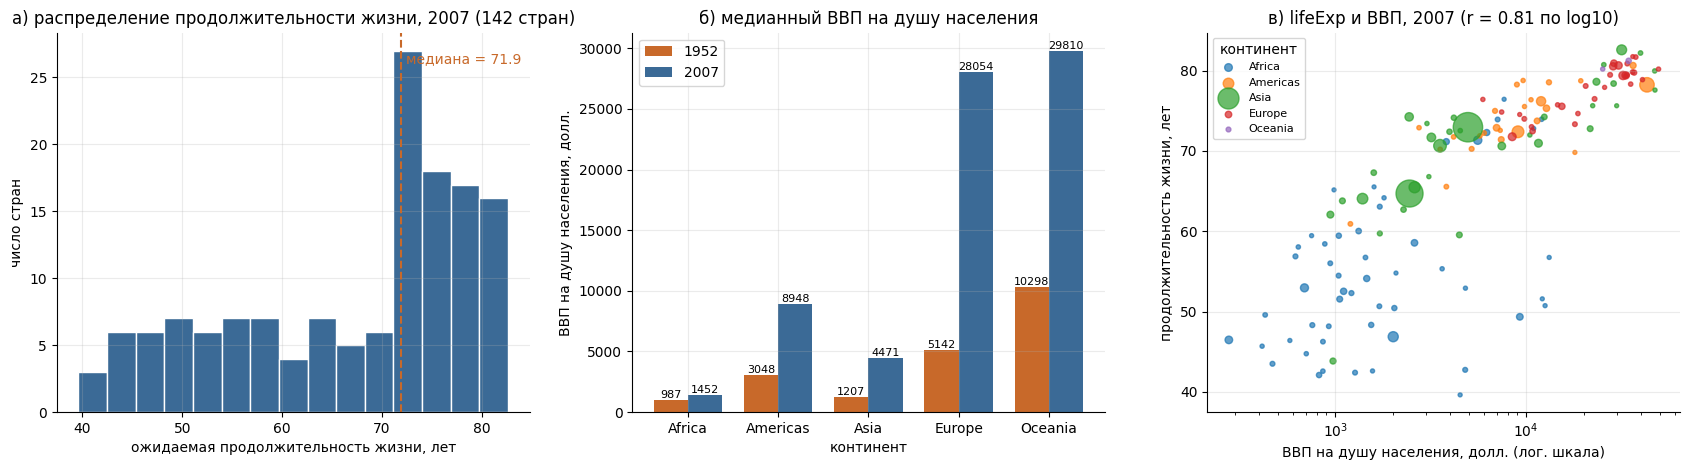

In [ ]:
# 5) построить не менее двух графиков разного типа (например, гистограмму и столбчатую
# диаграмму сводной таблицы), оформленных по образцу рис. 6;

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

# а) гистограмма продолжительности жизни 2007
ax[0].hist(d07["lifeExp"], bins=15, color="#3b6a96", edgecolor="white")
med = d07["lifeExp"].median()
ax[0].axvline(med, color="#c8692a", ls="--")
ax[0].text(med + 0.5, ax[0].get_ylim()[1] * 0.92, f"медиана = {med:.1f}", color="#c8692a")
ax[0].set_title(f"а) распределение продолжительности жизни, 2007 ({len(d07)} стран)")
ax[0].set_xlabel("ожидаемая продолжительность жизни, лет")
ax[0].set_ylabel("число стран")

# б) столбчатая диаграмма медианного ВВП 1952 vs 2007
g = gdp[[1952, 2007]]
x = np.arange(len(g)); w = 0.38
b1 = ax[1].bar(x - w/2, g[1952], w, label="1952", color="#c8692a")
b2 = ax[1].bar(x + w/2, g[2007], w, label="2007", color="#3b6a96")
ax[1].bar_label(b1, fmt="%.0f", fontsize=8); ax[1].bar_label(b2, fmt="%.0f", fontsize=8)
ax[1].set_xticks(x); ax[1].set_xticklabels(g.index)
ax[1].set_title("б) медианный ВВП на душу населения")
ax[1].set_xlabel("континент"); ax[1].set_ylabel("ВВП на душу населения, долл.")
ax[1].legend()

# в) диаграмма рассеяния с логарифмической осью
for cont, grp in d07.groupby("continent"):
    ax[2].scatter(grp["gdpPercap"], grp["lifeExp"], s=grp["pop"] / 3e6 + 8, alpha=0.7, label=cont)
ax[2].set_xscale("log")
ax[2].set_title(f"в) lifeExp и ВВП, 2007 (r = {r_log:.2f} по log10)")
ax[2].set_xlabel("ВВП на душу населения, долл. (лог. шкала)")
ax[2].set_ylabel("продолжительность жизни, лет")
ax[2].legend(title="континент", fontsize=8)

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
    a.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
# записать 4–6 выводов, каждый из которых опирается на конкретное число или график.

1. **Разрыв в продолжительности жизни.** В 2007 г. лидирует Япония (82,6 года), на последнем месте среди пяти худших Свазиленд (39,6 года): разница более 40 лет. Все пять худших стран (Свазиленд, Мозамбик, Замбия, Сьерра-Леоне, Лесото) африканские (пункт 4а).
2. **Африка почти не выросла по ввп.** Разрыв между континентами увеличился (пункт 4б).
3. **Связь дохода и продолжительности жизни нелинейная.** Корреляция `lifeExp` с `gdpPercap` равна 0,68, а с `log10(gdpPercap)` — 0,81; график с логарифмической осью (рис. в) показывает почти линейную зависимость. Рост дохода сильнее всего влияет на бедные страны, у богатых эффект насыщается. Это корреляция, а не доказательство причинности.
4. **Данные чистые, но неполные по выборке.** Пропусков и дубликатов нет, 142 страны × 12 лет = 1704 строки, но Океания представлена всего двумя странами (24 строки), поэтому выводы по ней ненадёжны.